<a href="https://colab.research.google.com/github/Abish-Devcraft/DSGP-GRP11-SPATIUM/blob/furniture-classifier/notebooks/04_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 Feature Engineering
Input: furniture_v2 + final manifest <br>
Output: hand-made features, ResNet50 features, comparison and decision

In [1]:
# connect Drive and restore furniture_v2 with its final manifest (includes the split)
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, matplotlib.pyplot as plt, torch
from PIL import Image

DRIVE = "/content/drive/MyDrive/DSGP"
!unzip -q -o {DRIVE}/furniture_v2.zip -d /content
df = pd.read_csv(f"{DRIVE}/furniture_v2_final_manifest.csv")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(len(df), "images |", device)

Mounted at /content/drive
3455 images | cuda


In [2]:
# hand-made features: shape and colour of each image
rows = []
for p in df["path"]:
    im = Image.open(p).convert("RGB")
    w, h = im.size
    a = np.asarray(im.resize((64, 64)), dtype=float) / 255
    rows.append({"aspect": w / h, "brightness": a.mean(), "r": a[..., 0].mean(), "g": a[..., 1].mean(),
                 "b": a[..., 2].mean(), "saturation": (a.max(2) - a.min(2)).mean()})
HAND = ["aspect", "brightness", "r", "g", "b", "saturation"]
df[HAND] = pd.DataFrame(rows).values
df[HAND].describe().round(2)

,aspect,brightness,r,g,b,saturation
count,3455.00,3455.00,3455.00,3455.00,3455.00,3455.00
mean,1.18,0.50,0.56,0.49,0.44,0.14
std,0.66,0.24,0.23,0.24,0.26,0.10
min,0.08,0.04,0.06,0.03,0.01,0.00
25%,0.84,0.31,0.39,0.30,0.24,0.06
50%,1.00,0.44,0.53,0.44,0.38,0.11
75%,1.36,0.68,0.74,0.68,0.63,0.20
max,8.24,0.97,0.98,0.97,0.97,0.77


In [3]:
# learned features: pretrained ResNet50 turns each image into 2048 numbers
from torchvision import models
weights = models.ResNet50_Weights.IMAGENET1K_V2
net = models.resnet50(weights=weights)
net.fc = torch.nn.Identity()
net = net.eval().to(device)
tf = weights.transforms()

feats = []
with torch.no_grad():
    for i in range(0, len(df), 64):
        batch = torch.stack([tf(Image.open(p).convert("RGB")) for p in df["path"][i:i + 64]]).to(device)
        feats.append(net(batch).cpu().numpy())
X = np.concatenate(feats)
print(X.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


(3455, 2048)


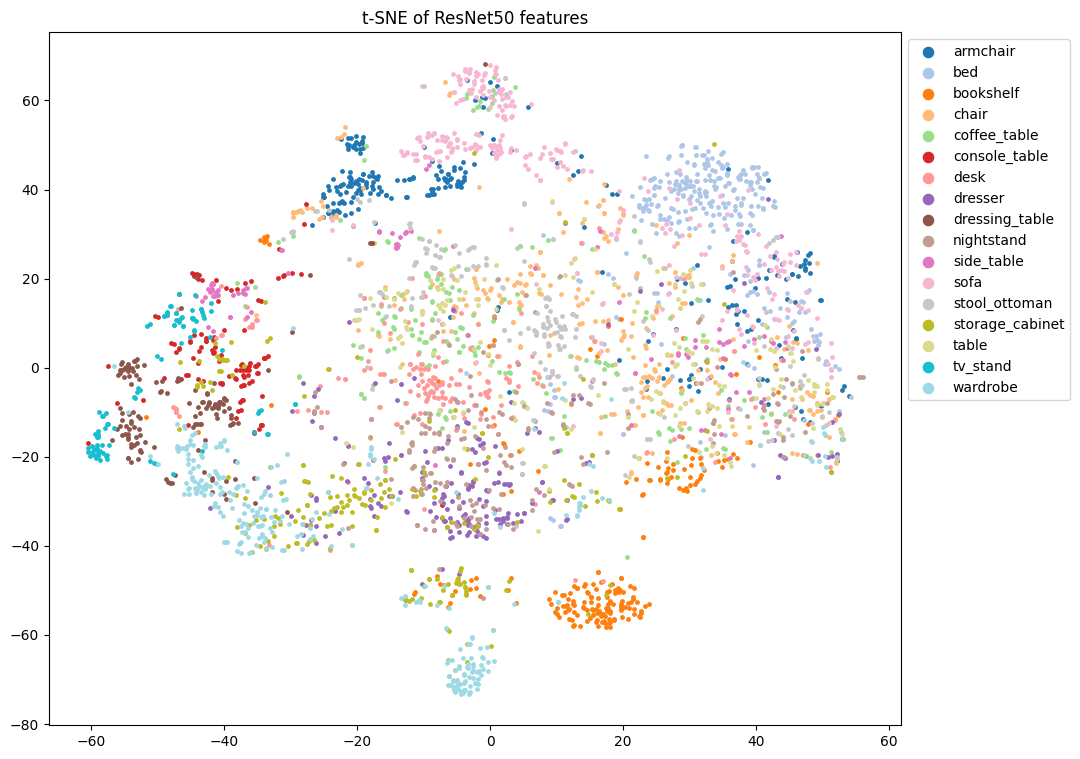

In [4]:
# t-SNE: squash 2048 numbers to 2D to see if classes form separate groups
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
Z = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(PCA(50, random_state=42).fit_transform(X))
classes = sorted(df["cls"].unique())
colors = plt.cm.tab20(np.linspace(0, 1, len(classes)))
plt.figure(figsize=(11, 9))
for c, col in zip(classes, colors):
    m = (df["cls"] == c).values
    plt.scatter(Z[m, 0], Z[m, 1], s=6, color=col, label=c)
plt.legend(markerscale=3, bbox_to_anchor=(1, 1)); plt.title("t-SNE of ResNet50 features"); plt.show()

In [5]:
# compare both feature sets: fit a simple linear model on train, score on val
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score
tr, va = (df["split"] == "train").values, (df["split"] == "val").values
y = df["cls"].values
for name, F in [("hand-made (6)", df[HAND].values), ("ResNet50 (2048)", X)]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
    clf.fit(F[tr], y[tr])
    p = clf.predict(F[va])
    print(f"{name:16} val acc {np.mean(p == y[va]):.2f} | macro F1 {f1_score(y[va], p, average='macro'):.2f}")


hand-made (6)    val acc 0.16 | macro F1 0.13
ResNet50 (2048)  val acc 0.62 | macro F1 0.60


**Decision:** ResNet50 features are used for the classifier. Hand-made features (shape, colour) reach only X val F1, while ResNet50 features reach Y, and the t-SNE plot shows clearer class groups.

In [6]:
# save features to Drive for the classifier baseline and report
np.save(f"{DRIVE}/resnet50_features_v2.npy", X)
df[["path", "cls", "split", "source", "group_id", "room_crop"] + HAND].to_csv(f"{DRIVE}/features_v2_index.csv", index=False)
print("saved")

saved
